In [18]:
from pathlib import Path
import sys
import math

import torch
import matplotlib.pyplot as plt

# 定位项目根目录
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.models.dncnn import DnCNN
from src.datasets.sidd_dataset import SIDDDataset

# 选择计算设备
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("项目目录：", PROJECT_ROOT)
print("当前设备：", device)

项目目录： D:\CodeRepository\graduation‑design
当前设备： cuda


In [19]:
# 最佳模型路径
MODEL_PATH = PROJECT_ROOT / "checkpoints/dncnn_sidd_best.pth"

# 创建模型
model = DnCNN(
    in_channels=3,
    features=64,
    depth=20
).to(device)

# 读取训练好的权重
state_dict = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

# 将权重加载到模型
model.load_state_dict(state_dict)

# 切换到推理模式
model.eval()

print("最佳模型加载成功！")

最佳模型加载成功！


In [20]:
# 创建验证数据集
dataset = SIDDDataset(split="val")

# 选择第 1 张验证图像
sample_index = 16

noisy, gt = dataset[sample_index]

# 增加 Batch 维度，并移动到 GPU
input_tensor = noisy.unsqueeze(0).to(device)

# 模型推理
with torch.no_grad():
    denoised = model(input_tensor)
    denoised = denoised.clamp(0, 1)

# 将输出转换回 CPU
denoised = denoised.squeeze(0).cpu()

print("带噪图像尺寸：", noisy.shape)
print("去噪图像尺寸：", denoised.shape)
print("真实图像尺寸：", gt.shape)

带噪图像尺寸： torch.Size([3, 256, 256])
去噪图像尺寸： torch.Size([3, 256, 256])
真实图像尺寸： torch.Size([3, 256, 256])


去噪前 PSNR：20.74 dB
去噪后 PSNR：26.35 dB
PSNR 提升：5.61 dB


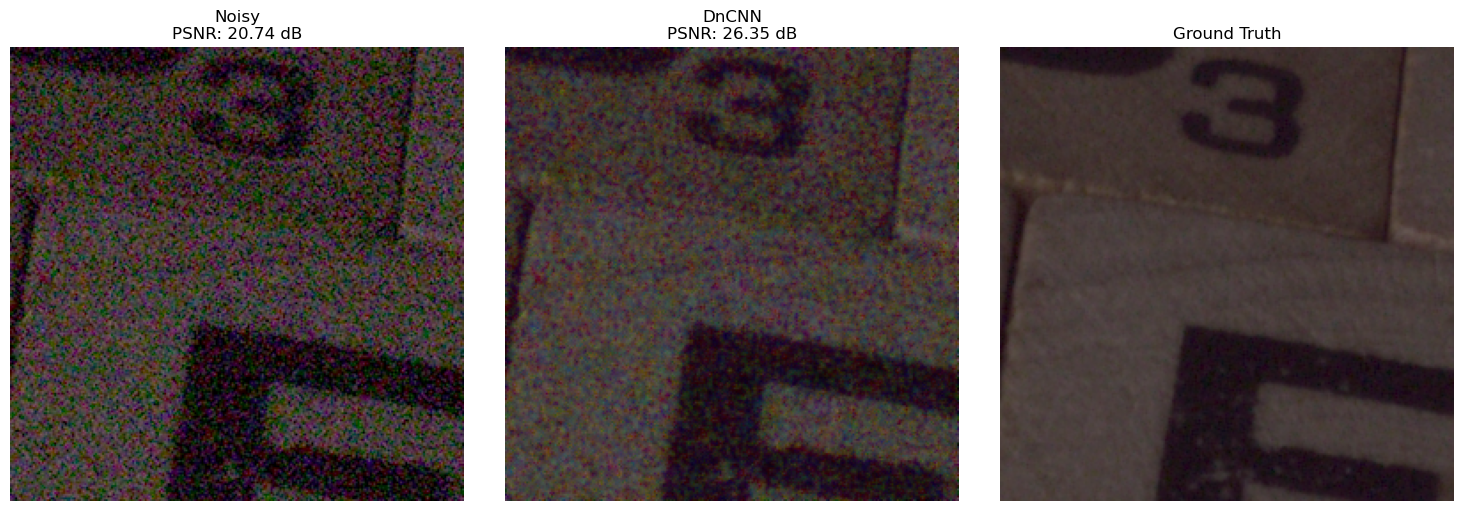

In [21]:
# PSNR 计算函数
def calculate_psnr(img1, img2):
    mse = torch.mean((img1 - img2) ** 2).item()
    return -10 * math.log10(max(mse, 1e-12))


# 计算指标
noisy_psnr = calculate_psnr(noisy, gt)
denoised_psnr = calculate_psnr(denoised, gt)

print(f"去噪前 PSNR：{noisy_psnr:.2f} dB")
print(f"去噪后 PSNR：{denoised_psnr:.2f} dB")
print(f"PSNR 提升：{denoised_psnr - noisy_psnr:.2f} dB")


# Tensor 转换为可显示图片
def to_image(tensor):
    return tensor.permute(1, 2, 0).numpy()


# 显示三张图像
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [noisy, denoised, gt]

titles = [
    f"Noisy\nPSNR: {noisy_psnr:.2f} dB",
    f"DnCNN\nPSNR: {denoised_psnr:.2f} dB",
    "Ground Truth"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(to_image(img))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import math
from statistics import mean
from skimage.metrics import structural_similarity
from src.datasets.sidd_dataset import SIDDDataset

# 加载完整验证集
dataset = SIDDDataset(split="val")

model.eval()

noisy_psnrs = []
denoised_psnrs = []
noisy_ssims = []
denoised_ssims = []
val_losses = []

def psnr(a, b):
    mse = torch.mean((a - b) ** 2).item()
    return -10 * math.log10(max(mse, 1e-12))

def ssim(a, b):
    a = a.permute(1, 2, 0).numpy()
    b = b.permute(1, 2, 0).numpy()
    return structural_similarity(
        a, b,
        data_range=1.0,
        channel_axis=2
    )

with torch.inference_mode():
    for i in range(len(dataset)):
        noisy, gt = dataset[i]

        # 推理
        output = model(noisy.unsqueeze(0).to(device))
        output = output.squeeze(0).cpu()

        # Val Loss 使用未裁剪的模型输出
        val_losses.append(
            torch.mean((output - gt) ** 2).item()
        )

        # PSNR、SSIM 使用 [0,1] 范围图像
        denoised = output.clamp(0, 1)

        noisy_psnrs.append(psnr(noisy, gt))
        denoised_psnrs.append(psnr(denoised, gt))

        noisy_ssims.append(ssim(noisy, gt))
        denoised_ssims.append(ssim(denoised, gt))

print(f"验证图像数量：{len(dataset)}")
print(f"Val Loss：{mean(val_losses):.6f}")
print(f"去噪前 PSNR：{mean(noisy_psnrs):.2f} dB")
print(f"去噪后 PSNR：{mean(denoised_psnrs):.2f} dB")
print(f"PSNR 提升：{mean(denoised_psnrs) - mean(noisy_psnrs):.2f} dB")
print(f"去噪前 SSIM：{mean(noisy_ssims):.4f}")
print(f"去噪后 SSIM：{mean(denoised_ssims):.4f}")

验证图像数量：46
Val Loss：0.000754
去噪前 PSNR：29.33 dB
去噪后 PSNR：32.90 dB
PSNR 提升：3.57 dB
去噪前 SSIM：0.5811
去噪后 SSIM：0.7501
